In [6]:
import glob, os, re
from datetime import datetime
import numpy as np, netCDF4 as nc, pandas as pd
import matplotlib.pyplot as plt

run = "/scratch/alpine/battobrah@xsede.org/Rice_NMT_Snow/upper_colorado_test025/experiments/simulations/MSWX_3h_Snow_Project3_pp_upper_colorado_test025_time_check"
cids = [1, 2, 3, 4]
dt_h = 3.0
day0 = pd.Timestamp("2016-06-20")      # period shown in the time-series plots
ndays = 4


def load_cid(cid):
    # forcing + HRU longitudes
    with nc.Dataset(f"{run}/{cid}/input_file.nc") as ds:
        lons = np.array(ds.groups["parameters"]["lons"][:])
        met = ds.groups["meteorology"]
        tv = met["time"]
        f_times = pd.to_datetime([d.isoformat() for d in
                                  nc.num2date(tv[:], tv.units, getattr(tv, "calendar", "standard"))])
        f_sw = np.array(met["swdown"][:])
    # model output (time from file name + dt)
    files = sorted(glob.glob(f"{run}/output_data/{cid}/*.nc"))
    times, out = [], {v: [] for v in ["swdn", "swdn_3d", "swnet", "cosz"]}
    for f in files:
        start = datetime.strptime(re.search(r"(\d{4}-\d{2}-\d{2})", os.path.basename(f)).group(1), "%Y-%m-%d")
        with nc.Dataset(f) as ds:
            g = ds.groups["data"]
            n = g["swdn"].shape[0]
            for v in out:
                if v in g.variables:
                    out[v].append(np.ma.asarray(g[v][:]).filled(np.nan))
        times.append(pd.date_range(start, periods=n, freq=f"{int(dt_h)}h"))
    o_times = times[0].append(times[1:]) if len(times) > 1 else times[0]
    out = {v: np.concatenate(a, axis=0) for v, a in out.items() if a}
    return dict(cid=cid, lon=float(np.nanmean(lons)), nhru=lons.size,
                f_times=f_times, f_sw=f_sw, o_times=o_times, out=out)


data = {c: load_cid(c) for c in cids}
for c, d in data.items():
    print(f"CID {c}: {d['nhru']} HRUs | mean lon {d['lon']:.2f} | forcing {len(d['f_times'])} steps | "
          f"output {len(d['o_times'])} steps | vars {list(d['out'])}")

CID 1: 20 HRUs | mean lon -107.35 | forcing 8744 steps | output 8744 steps | vars ['swdn', 'swnet', 'cosz']
CID 2: 20 HRUs | mean lon -107.11 | forcing 8744 steps | output 8744 steps | vars ['swdn', 'swnet', 'cosz']
CID 3: 20 HRUs | mean lon -107.37 | forcing 8744 steps | output 8744 steps | vars ['swdn', 'swnet', 'cosz']
CID 4: 20 HRUs | mean lon -107.11 | forcing 8744 steps | output 8744 steps | vars ['swdn', 'swnet', 'cosz']


In [7]:
rows = []
for c, d in data.items():
    n = min(len(d["f_times"]), len(d["o_times"]))
    fm = np.nanmean(d["f_sw"][:n], axis=1)
    om = np.nanmean(d["out"]["swdn"][:n], axis=1)
    res = {}
    for lag in range(-3, 4):
        if lag >= 0:
            res[lag] = np.nanmean(np.abs(om[lag:] - fm[:n - lag]))
        else:
            res[lag] = np.nanmean(np.abs(om[:n + lag] - fm[-lag:]))
    best = min(res, key=res.get)
    rows.append({"CID": c, "best lag (steps)": best, "error at best lag": round(res[best], 3),
                 "error at lag 0": round(res[0], 3),
                 "first forcing": d["f_times"][0], "first output": d["o_times"][0]})
print(pd.DataFrame(rows).to_string(index=False))

 CID  best lag (steps)  error at best lag  error at lag 0 first forcing first output
   1                 0                0.0             0.0    2014-01-01   2014-01-01
   2                 0                0.0             0.0    2014-01-01   2014-01-01
   3                 0                0.0             0.0    2014-01-01   2014-01-01
   4                 0                0.0             0.0    2014-01-01   2014-01-01


In [8]:
cycles = {}
for c, d in data.items():
    lst = ((d["o_times"].hour + d["o_times"].minute / 60 + d["lon"] / 15.0) % 24)
    cols = {"lst": np.round(lst, 1), "swdn": np.nanmean(d["out"]["swdn"], axis=1)}
    if "swdn_3d" in d["out"]:
        cols["swdn_3d"] = np.nanmean(d["out"]["swdn_3d"], axis=1)
    if "cosz" in d["out"]:
        cols["cosz"] = np.nanmean(d["out"]["cosz"], axis=1)
    df = pd.DataFrame(cols)
    d["df"] = df
    cycles[c] = df.groupby("lst").mean().round(2)
    print(f"\n=== CID {c} (lon {d['lon']:.2f}) ===")
    print(cycles[c])


=== CID 1 (lon -107.35) ===
            swdn  cosz
lst                   
1.8     0.000000 -0.67
4.8    31.370001 -0.22
7.8   348.399994  0.35
10.8  618.219971  0.72
13.8  465.760010  0.67
16.8  112.879997  0.23
19.8    0.450000 -0.35
22.8    0.000000 -0.72

=== CID 2 (lon -107.11) ===
            swdn  cosz
lst                   
1.9     0.000000 -0.67
4.9    32.220001 -0.22
7.9   355.660004  0.35
10.9  629.330017  0.72
13.9  471.799988  0.67
16.9  113.099998  0.22
19.9    0.430000 -0.35
22.9    0.000000 -0.72

=== CID 3 (lon -107.37) ===
            swdn  cosz
lst                   
1.8     0.000000 -0.67
4.8    32.340000 -0.22
7.8   357.290009  0.35
10.8  636.719971  0.72
13.8  483.709991  0.67
16.8  116.980003  0.22
19.8    0.490000 -0.35
22.8    0.000000 -0.72

=== CID 4 (lon -107.11) ===
            swdn  cosz
lst                   
1.9     0.000000 -0.66
4.9    33.520000 -0.22
7.9   367.890015  0.35
10.9  652.940002  0.72
13.9  493.040009  0.67
16.9  117.900002  0.22
19.9    0.

In [9]:
rows = []
for c, d in data.items():
    df = d["df"]
    if "cosz" not in df:
        print(f"CID {c}: no cosz in output, skipped"); continue
    night = df["cosz"] <= 0
    r = {"CID": c, "steps": len(df), "cosz<=0": int(night.sum()),
         "night & swdn>10": int((night & (df["swdn"] > 10)).sum())}
    r["% of all steps"] = round(100 * r["night & swdn>10"] / len(df), 1)
    r["mean swdn at those steps (W m-2)"] = round(df.loc[night & (df["swdn"] > 10), "swdn"].mean(), 1)
    if "swdn_3d" in df:
        r["night & swdn_3d>10"] = int((night & (df["swdn_3d"] > 10)).sum())
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
if not any("swdn_3d" in d["out"] for d in data.values()):
    print("\nNote: no CID has 'swdn_3d' in its output (PP run), so only swdn is checked.")

 CID  steps  cosz<=0  night & swdn>10  % of all steps  mean swdn at those steps (W m-2)
   1   8744     4370              539             6.2                         37.299999
   2   8744     4370              539             6.2                         37.799999
   3   8744     4370              539             6.2                         38.000000
   4   8744     4370              545             6.2                         38.299999

Note: no CID has 'swdn_3d' in its output (PP run), so only swdn is checked.


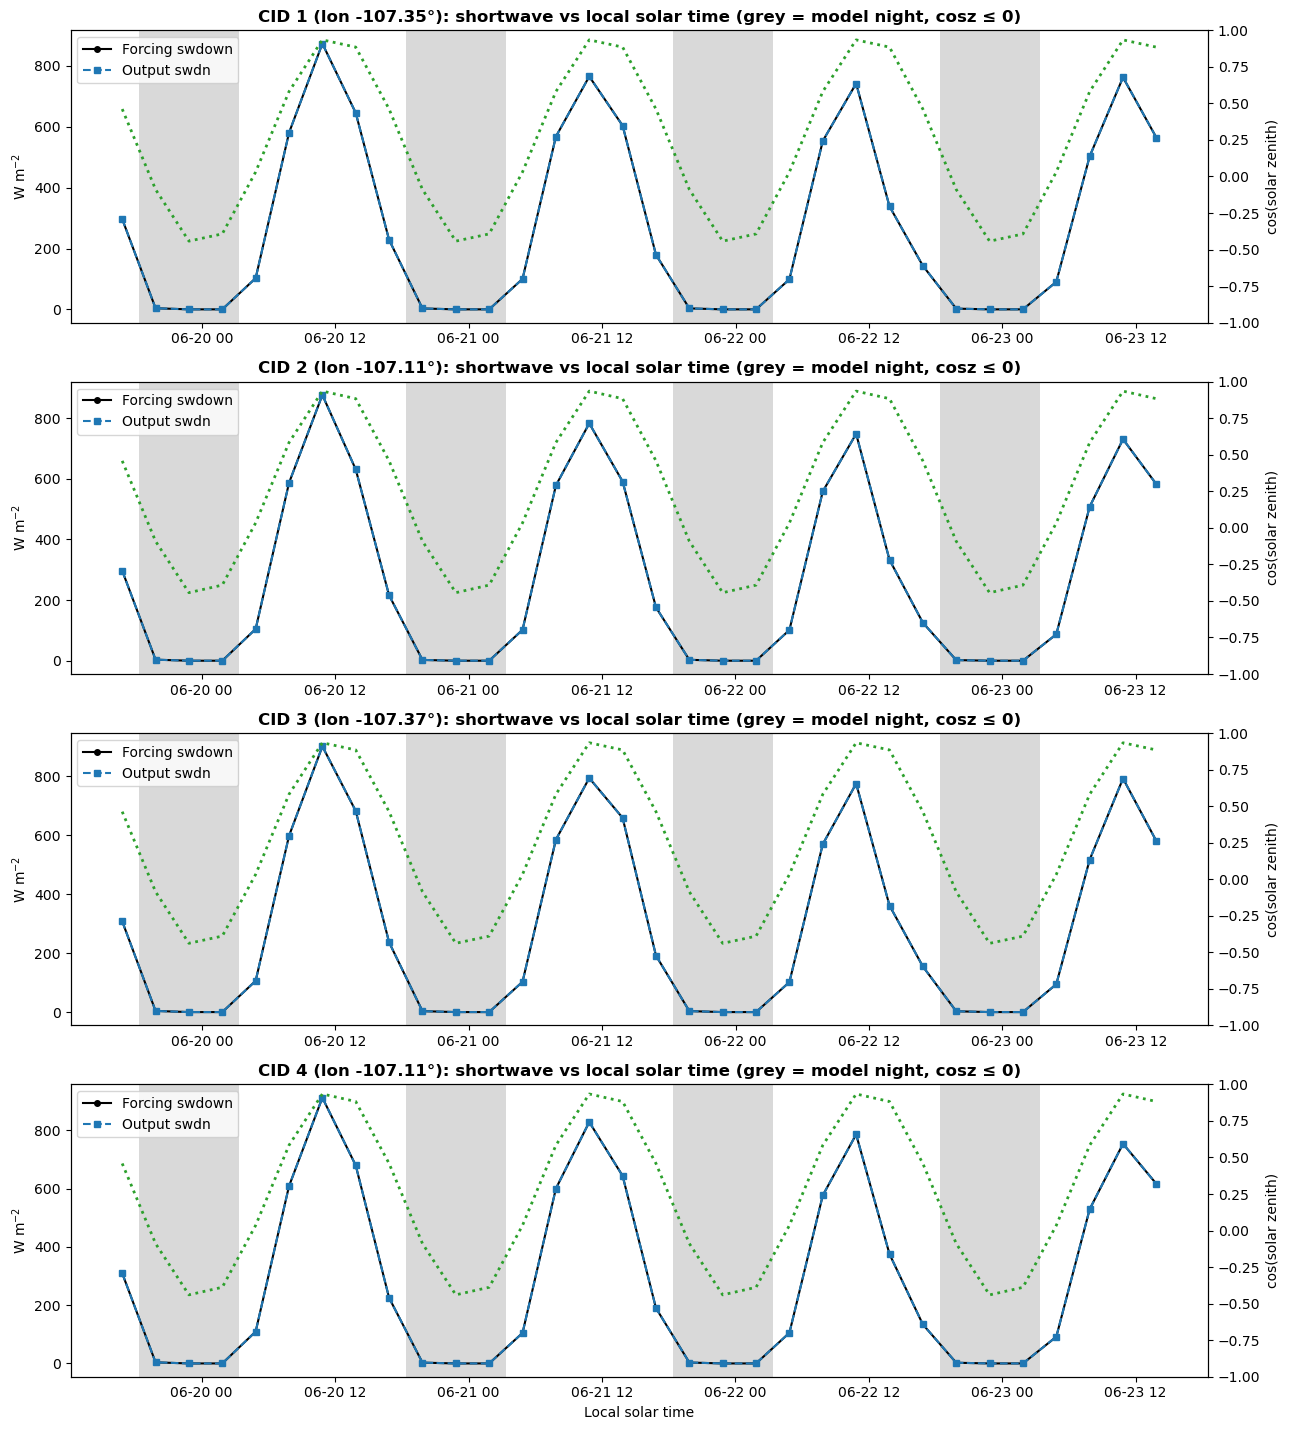

In [10]:
fig, axes = plt.subplots(len(cids), 1, figsize=(13, 3.6 * len(cids)), sharex=False)
for ax, (c, d) in zip(np.atleast_1d(axes), data.items()):
    m = (d["o_times"] >= day0) & (d["o_times"] < day0 + pd.Timedelta(days=ndays))
    t_utc = d["o_times"][m]
    t_lst = t_utc + pd.to_timedelta(d["lon"] / 15.0, unit="h")
    sw = np.nanmean(d["out"]["swdn"][m], axis=1)
    fsw = pd.Series(np.nanmean(d["f_sw"], axis=1), index=d["f_times"]).reindex(t_utc).values

    ax.plot(t_lst, fsw, "k-o", ms=4, label="Forcing swdown")
    ax.plot(t_lst, sw, "C0--s", ms=4, label="Output swdn")
    if "swdn_3d" in d["out"]:
        ax.plot(t_lst, np.nanmean(d["out"]["swdn_3d"][m], axis=1), "C3-^", ms=4, label="Output swdn_3d")
    if "cosz" in d["out"]:
        cz = np.nanmean(d["out"]["cosz"][m], axis=1)
        for t, z in zip(t_lst, cz):
            if z <= 0:
                ax.axvspan(t - pd.Timedelta(hours=1.5), t + pd.Timedelta(hours=1.5), color="0.85", lw=0)
        ax2 = ax.twinx()
        ax2.plot(t_lst, cz, "C2:", lw=2)
        ax2.set_ylim(-1, 1); ax2.set_ylabel("cos(solar zenith)")
    ax.set_ylabel("W m$^{-2}$")
    ax.set_title(f"CID {c} (lon {d['lon']:.2f}°): shortwave vs local solar time "
                 f"(grey = model night, cosz ≤ 0)", fontweight="bold")
    ax.legend(loc="upper left")
axes[-1].set_xlabel("Local solar time")
plt.tight_layout(); plt.show()

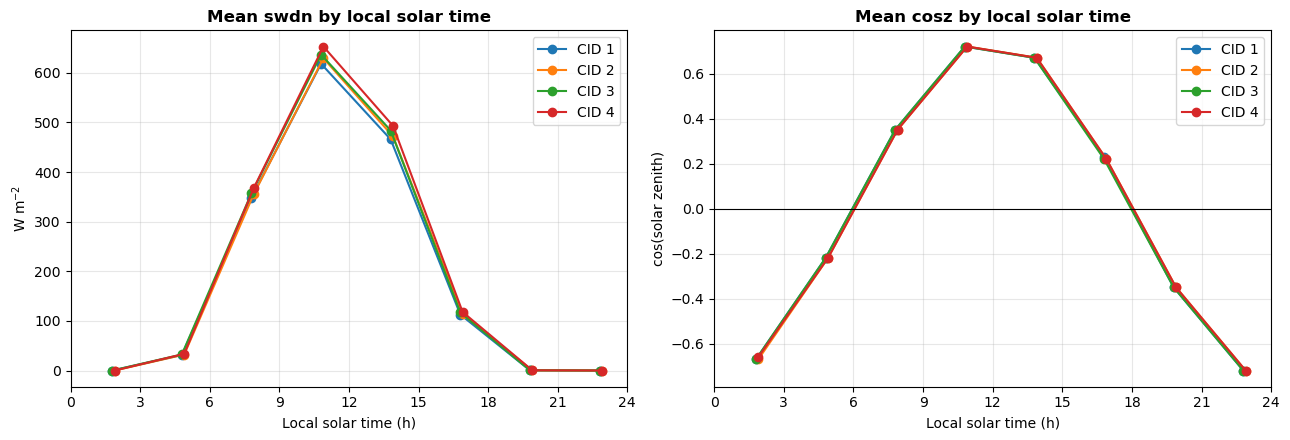

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for c, cyc in cycles.items():
    ax[0].plot(cyc.index, cyc["swdn"], "-o", label=f"CID {c}")
    if "cosz" in cyc:
        ax[1].plot(cyc.index, cyc["cosz"], "-o", label=f"CID {c}")
ax[0].set_title("Mean swdn by local solar time", fontweight="bold")
ax[0].set_xlabel("Local solar time (h)"); ax[0].set_ylabel("W m$^{-2}$")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Mean cosz by local solar time", fontweight="bold")
ax[1].set_xlabel("Local solar time (h)"); ax[1].set_ylabel("cos(solar zenith)")
for a in ax:
    a.set_xticks(range(0, 25, 3)); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

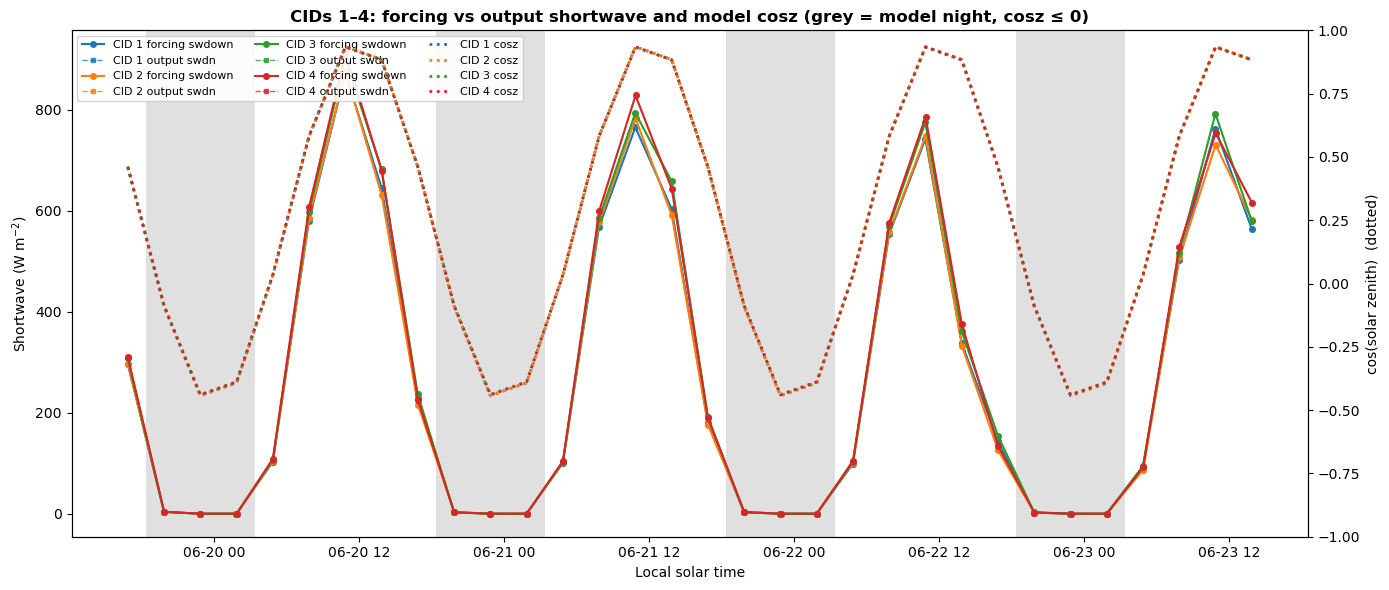

In [12]:
colors = ["C0", "C1", "C2", "C3"]

fig, ax = plt.subplots(figsize=(14, 6))
ax2 = ax.twinx()

shade_done = False
for (c, d), col in zip(data.items(), colors):
    m = (d["o_times"] >= day0) & (d["o_times"] < day0 + pd.Timedelta(days=ndays))
    t_utc = d["o_times"][m]
    t_lst = t_utc + pd.to_timedelta(d["lon"] / 15.0, unit="h")       # each CID's local solar time

    sw  = np.nanmean(d["out"]["swdn"][m], axis=1)
    fsw = pd.Series(np.nanmean(d["f_sw"], axis=1), index=d["f_times"]).reindex(t_utc).values

    ax.plot(t_lst, fsw, "-o", color=col, ms=4, lw=1.5, label=f"CID {c} forcing swdown")
    ax.plot(t_lst, sw, "--s", color=col, ms=3, lw=1, alpha=0.8, label=f"CID {c} output swdn")
    if "swdn_3d" in d["out"]:
        ax.plot(t_lst, np.nanmean(d["out"]["swdn_3d"][m], axis=1), "-^", color=col, ms=3,
                lw=1, label=f"CID {c} output swdn_3d")

    if "cosz" in d["out"]:
        cz = np.nanmean(d["out"]["cosz"][m], axis=1)
        ax2.plot(t_lst, cz, ":", color=col, lw=2, label=f"CID {c} cosz")
        if not shade_done:                       # shade model night once (CID 1 as reference)
            for t, z in zip(t_lst, cz):
                if z <= 0:
                    ax.axvspan(t - pd.Timedelta(hours=1.5), t + pd.Timedelta(hours=1.5),
                               color="0.88", lw=0, zorder=0)
            shade_done = True

ax.set_xlabel("Local solar time")
ax.set_ylabel("Shortwave (W m$^{-2}$)")
ax2.set_ylabel("cos(solar zenith)  (dotted)")
ax2.set_ylim(-1, 1)
ax.set_title("CIDs 1–4: forcing vs output shortwave and model cosz "
             "(grey = model night, cosz ≤ 0)", fontweight="bold")

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", ncol=3, fontsize=8, framealpha=0.9)
plt.tight_layout()
plt.show()

In [13]:
def cosz_model(times_utc, lat, lon):
    """Same formula as CALC_DECLIN (without the +DT shift)."""
    deg = np.pi / 180.0
    doy = times_utc.dayofyear.values - 1
    gmt = times_utc.hour.values + times_utc.minute.values / 60.0
    julian = doy + gmt / 24.0
    sxlong = np.where(julian >= 80, 360/365*(julian - 80), 360/365*(julian + 285)) * deg
    declin = np.arcsin(np.sin(23.5*deg) * np.sin(sxlong))
    tloc = np.mod(gmt + lon / 15.0 + 24.0, 24.0)
    hrang = 15.0 * (tloc - 12.0) * deg
    return np.sin(lat*deg)*np.sin(declin) + np.cos(lat*deg)*np.cos(declin)*np.cos(hrang)


rows = []
for c, d in data.items():
    with nc.Dataset(f"{run}/{c}/input_file.nc") as ds:
        lat = float(np.nanmean(ds.groups["parameters"]["lats"][:]))
    t = d["o_times"]
    sw = np.nanmean(d["out"]["swdn"], axis=1)

    # cosz at the time stamp vs averaged over the 3-hour window (10-min samples)
    cz_start = cosz_model(t, lat, d["lon"])
    offsets = np.arange(0, 180, 10)                     # minutes into the window
    cz_win = np.mean([np.maximum(cosz_model(t + pd.Timedelta(minutes=int(m)), lat, d["lon"]), 0)
                      for m in offsets], axis=0)

    rows.append({
        "CID": c,
        "SW>10 & cosz(start)<=0": int(((cz_start <= 0) & (sw > 10)).sum()),
        "SW>10 & sun below horizon whole window": int(((cz_win <= 0) & (sw > 10)).sum()),
        "max SW when sun down whole window": round(float(np.nanmax(np.where(cz_win <= 0, sw, np.nan))), 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

 CID  SW>10 & cosz(start)<=0  SW>10 & sun below horizon whole window  max SW when sun down whole window
   1                     539                                     104                              30.87
   2                     539                                     104                              31.82
   3                     539                                     103                              31.28
   4                     545                                     112                              33.71


In [14]:
def cosz_window(t, lat, lon, start_offset_h, length_h=3.0, step_min=10):
    """Mean of max(cosz,0) over [t+offset, t+offset+length]."""
    mins = np.arange(0, int(length_h * 60), step_min)
    return np.mean([np.maximum(cosz_model(t + pd.Timedelta(hours=start_offset_h, minutes=int(m)),
                                          lat, lon), 0) for m in mins], axis=0)

for c, d in data.items():
    with nc.Dataset(f"{run}/{c}/input_file.nc") as ds:
        lat = float(np.nanmean(ds.groups["parameters"]["lats"][:]))
    t = d["o_times"]
    sw = np.nanmean(d["out"]["swdn"], axis=1)

    # (a) when do the unexplained cases occur? (assumed window = time stamp -> +3 h)
    cz0 = cosz_window(t, lat, d["lon"], 0.0)
    bad = (cz0 <= 0) & (sw > 10)
    lst = np.round((t.hour + d["lon"] / 15.0) % 24, 1)
    print(f"\n=== CID {c} (lat {lat:.2f}, lon {d['lon']:.2f}) ===")
    print("Unexplained cases by local solar time of the time stamp:",
          pd.Series(lst[bad]).value_counts().sort_index().to_dict())
    print("...and by month:", pd.Series(t[bad].month).value_counts().sort_index().to_dict())

    # (b) which window offset fits the forcing best?
    print(" offset(h)  SW>10 in dark windows   SW<1 in sunlit windows (cosz_mean>0.1)")
    for off in np.arange(-3.0, 3.01, 0.5):
        czw = cosz_window(t, lat, d["lon"], off)
        n_dark = int(((czw <= 0) & (sw > 10)).sum())
        n_lit = int(((czw > 0.1) & (sw < 1)).sum())
        print(f"   {off:+4.1f}         {n_dark:6d}                  {n_lit:6d}")


=== CID 1 (lat 38.13, lon -107.35) ===
Unexplained cases by local solar time of the time stamp: {16.8: 104}
...and by month: {1: 50, 11: 11, 12: 43}
 offset(h)  SW>10 in dark windows   SW<1 in sunlit windows (cosz_mean>0.1)
   -3.0            567                     223
   -2.5            303                      43
   -2.0            148                       0
   -1.5             28                       0
   -1.0              0                       0
   -0.5              0                       0
   +0.0            104                       0
   +0.5            278                      17
   +1.0            428                      95
   +1.5            575                     351
   +2.0            731                     582
   +2.5           1022                     762
   +3.0           1185                     909

=== CID 2 (lat 38.11, lon -107.11) ===
Unexplained cases by local solar time of the time stamp: {16.9: 104}
...and by month: {1: 54, 11: 12, 12: 38}
 offset(h)  SW